# Continuum fit -- SDSS J172637.24+264127.6

Goal: fit the continuum of the SDSS spectrum of the A0 star
SDSS J172637.24+264127.6 (`spec-lite-2182-53905-0101.fits`, see
`MAST_query.ipynb`) with `continuum.fit_continuum`, check it with the
data alone, and normalise the spectrum for the line fitting. The checks
against a known synthetic continuum are in `tests/test_continuum.py`
(run `pytest`). Wavelengths in Angstrom (vacuum).

Method: cubic spline with knots every `knot_spacing` Angstrom, weighted
by 1/sigma. Pixels more than `clip_low` sigma below the fit are
rejected, and the spline is refitted until convergence. Only pixels below
are clipped, because absorption only removes flux: the first fits run through the lines,
below the true continuum, so a cut above would reject the continuum
itself. Every pixel is re-tested at each iteration, so the fit rises
step by step to the continuum.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spectral_diag.continuum import ContinuumSettings, fit_continuum, normalise
from spectral_diag.equivalent_width import measure_ew
from spectral_diag.sdss_reader import read_sdss_spec

In [2]:
spec = read_sdss_spec(Path("../data/mast/spec-lite-2182-53905-0101.fits"))
print(f"{spec.meta['class']} {spec.meta['subclass']}, z = {spec.meta['z']:.5f}")
print(f"{spec.wave.size} pixels, {spec.wave.min():.1f}-{spec.wave.max():.1f} A")

STAR A0, z = -0.00012
3772 pixels, 3811.5-9206.6 A


## 1. Fit

Default settings. Red points: pixels clipped in the final fit, a
first, line-list-free view of where the absorption is.

ContinuumSettings(knot_spacing=250.0, clip_low=2.0, max_iter=20)
3159 of 3772 pixels used, 10 iterations, converged
median relative continuum error: 0.0013


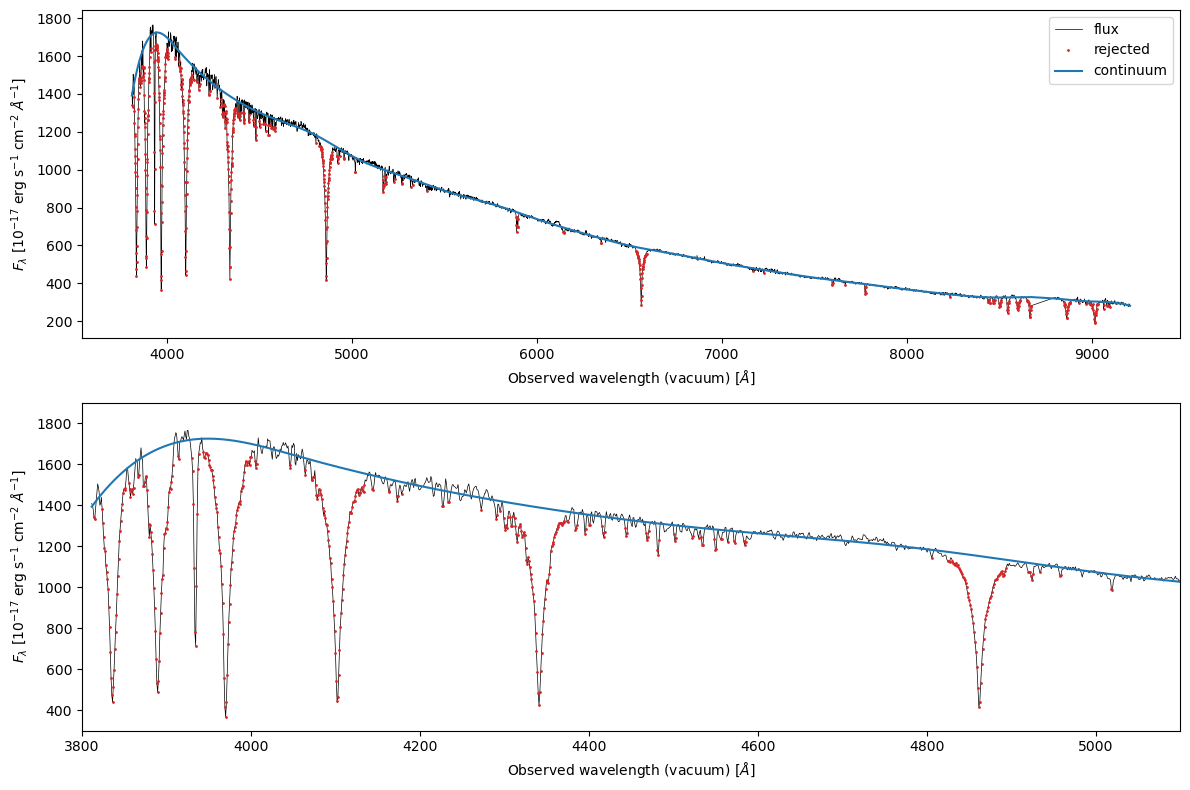

In [3]:
# Zoom on the blue end, where the absorption is strongest (Angstrom,
# flux units)
BLUE_WAVE_RANGE = (3800, 5100)
BLUE_FLUX_RANGE = (300, 1900)

settings = ContinuumSettings()
print(settings)
fit = fit_continuum(spec, settings)
continuum, used = fit.continuum, fit.used
print(f"{used.sum()} of {used.size} pixels used, {fit.n_iter} iterations, {fit.status}")
print(f"median relative continuum error: {np.nanmedian(fit.error / continuum):.4f}")


def plot_fit(ax, spec, continuum, used):
    """Plot flux, rejected pixels and continuum on `ax`.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    spec : Spectrum
    continuum : array
    used : array of bool
    """
    ax.plot(spec.wave, spec.flux, lw=0.5, color="k", label="flux")
    ax.plot(spec.wave[~used], spec.flux[~used], ".", ms=2, color="C3",
            label="rejected")
    ax.plot(spec.wave, continuum, color="C0", label="continuum")
    ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
    ax.set_ylabel(r"$F_\lambda$ [$10^{-17}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]")


fig, (ax_full, ax_blue) = plt.subplots(2, 1, figsize=(12, 8))
plot_fit(ax_full, spec, continuum, used)
ax_full.legend()
plot_fit(ax_blue, spec, continuum, used)
ax_blue.set_xlim(*BLUE_WAVE_RANGE)
ax_blue.set_ylim(*BLUE_FLUX_RANGE)
plt.tight_layout()
plt.show()

Here the continuum covers the whole spectrum. If the first or last
pixels were clipped, `fit_continuum` would leave the continuum as NaN
beyond the used pixels instead of extrapolating the spline, which
diverges.

Below ~3900 A the spline follows the overlapping wings of the higher
Balmer lines as they converge towards the series limit at 3646 A: no
pixel there reaches the continuum, so the fit is too low. The line
fitting will correct it with a local continuum.

## 2. Zoom on the difficult regions

- Hbeta and Halpha: the broad lines whose EW depends most on the
  continuum.
- 6800-7700 A: absorption bands of the Earth's atmosphere (O2 near 6870
  and 7600 A). They are rejected like lines, but they do not come from
  the star.

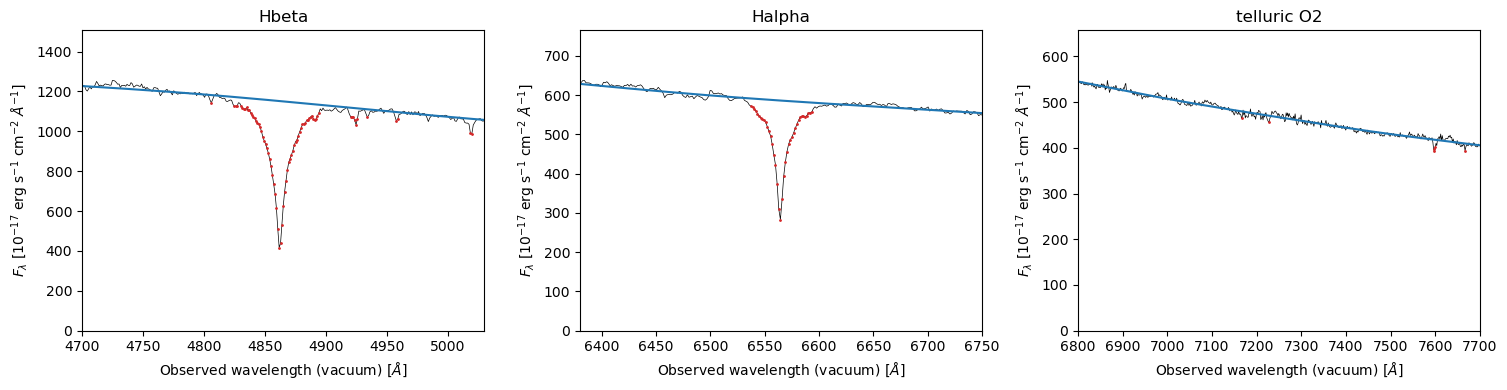

In [4]:
# (name, first wavelength, last wavelength), Angstrom
ZOOM_REGIONS = [
    ("Hbeta", 4700, 5030),
    ("Halpha", 6380, 6750),
    ("telluric O2", 6800, 7700),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, first_wave, last_wave) in zip(axes, ZOOM_REGIONS):
    in_region = (spec.wave > first_wave) & (spec.wave < last_wave)
    plot_fit(ax, spec, continuum, used)
    ax.set_xlim(first_wave, last_wave)
    ax.set_ylim(0, 1.2 * np.nanmax(spec.flux[in_region]))
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 3. Do the used pixels look like pure noise?

If the continuum is right, the used pixels differ from it by noise only,
so `deviation = (flux - continuum) / error`:
- is centred on 0,
- shows no large-scale pattern: averaged over 200 A bins,
  `flux / continuum - 1` should stay within a few times its own error.
  A wave in these bin averages would mean the spline misses a real bend
  of the continuum, or follows something it should not.

used pixels: mean deviation +0.01, std 0.77


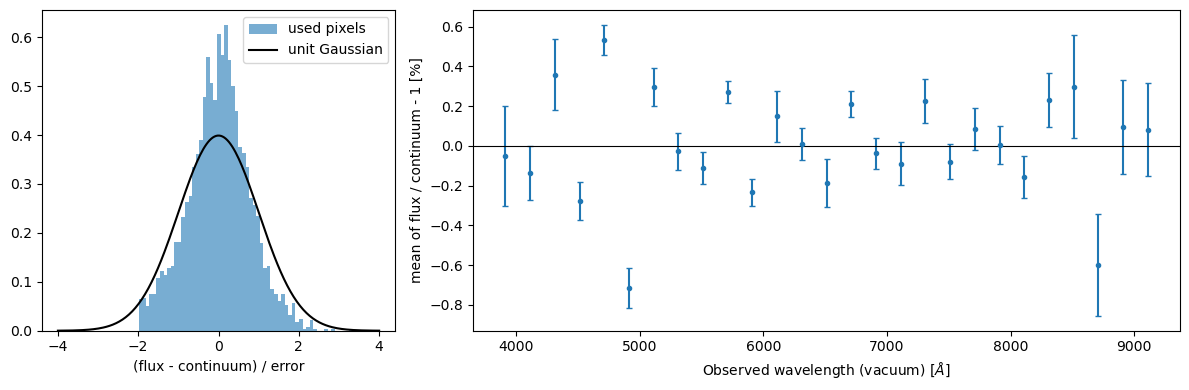

200 A bins more than 3 errors away from 0:
  4612-4812 A: +0.53% (+7.1 errors)
  4812-5012 A: -0.72% (-7.0 errors)
  5012-5212 A: +0.30% (+3.1 errors)
  5612-5812 A: +0.27% (+5.0 errors)
  5812-6012 A: -0.23% (-3.6 errors)
  6612-6812 A: +0.21% (+3.2 errors)


In [5]:
# Width of the bins in which the used pixels are averaged, Angstrom
BIN_WIDTH = 200.0
# Bins with fewer used pixels are skipped
MIN_PIXELS_PER_BIN = 20
# A bin is flagged if its mean is more than this many errors from 0
MAX_BIN_PULL = 3.0

deviation = ((spec.flux - continuum) / spec.error)[used]
print(f"used pixels: mean deviation {deviation.mean():+.2f}, std {deviation.std():.2f}")

bin_edges = np.arange(spec.wave.min(), spec.wave.max() + BIN_WIDTH, BIN_WIDTH)
bin_centres, bin_means, bin_errors = [], [], []
for first_wave, last_wave in zip(bin_edges[:-1], bin_edges[1:]):
    in_bin = used & (spec.wave >= first_wave) & (spec.wave < last_wave)
    if in_bin.sum() < MIN_PIXELS_PER_BIN:
        continue
    relative_excess = spec.flux[in_bin] / continuum[in_bin] - 1
    bin_centres.append((first_wave + last_wave) / 2)
    bin_means.append(relative_excess.mean())
    bin_errors.append(relative_excess.std() / np.sqrt(in_bin.sum()))
bin_centres = np.array(bin_centres)
bin_means = np.array(bin_means)
bin_errors = np.array(bin_errors)

fig, (ax_histogram, ax_bins) = plt.subplots(
    1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]}
)
ax_histogram.hist(deviation, bins=60, density=True, alpha=0.6, label="used pixels")
gaussian_x = np.linspace(-4, 4, 200)
unit_gaussian = np.exp(-(gaussian_x**2) / 2) / np.sqrt(2 * np.pi)
ax_histogram.plot(gaussian_x, unit_gaussian, color="k", label="unit Gaussian")
ax_histogram.set_xlabel("(flux - continuum) / error")
ax_histogram.legend()
ax_bins.errorbar(bin_centres, 100 * bin_means, 100 * bin_errors, fmt="o", ms=3, capsize=2)
ax_bins.axhline(0, color="k", lw=0.8)
ax_bins.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
ax_bins.set_ylabel("mean of flux / continuum - 1 [%]")
plt.tight_layout()
plt.show()

print(f"{BIN_WIDTH:.0f} A bins more than {MAX_BIN_PULL:.0f} errors away from 0:")
for centre, mean, error in zip(bin_centres, bin_means, bin_errors):
    if abs(mean / error) > MAX_BIN_PULL:
        first_wave = centre - BIN_WIDTH / 2
        last_wave = centre + BIN_WIDTH / 2
        print(f"  {first_wave:.0f}-{last_wave:.0f} A: {mean:+.2%} ({mean / error:+.1f} errors)")

- The histogram is narrower than the unit Gaussian. The pixel errors of
  the SDSS co-added spectrum look too large; a likely reason is that
  resampling onto the final grid correlates neighbouring pixels, which
  lowers the pixel-to-pixel scatter without lowering the errors (see
  Limitations).
- Overall the used pixels are centred on the continuum, but a few 200 A
  bins are off by several errors (less than 1%). The clearest is the
  bin containing Hbeta: its used pixels sit on average *below* the
  continuum. Those are the outer wings of Hbeta, too shallow to be
  rejected pixel by pixel, so they stay in the fit; the neighbouring
  bins swing the other way because the spline bends to follow them.

## 4. Knot spacing

The main parameter. Too small: the spline has the freedom to follow
the broad lines and eats part of their equivalent width. Too large: it
cannot follow the real shape of the continuum.

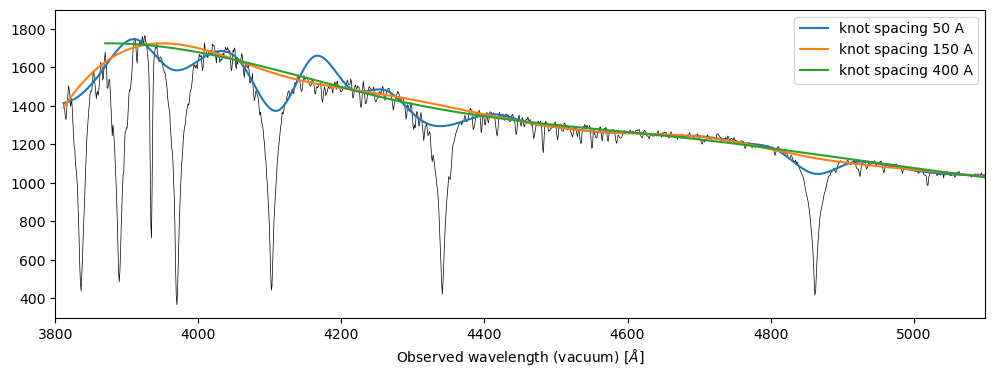

In [6]:
KNOT_SPACINGS = [50.0, 150.0, 400.0]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spec.wave, spec.flux, lw=0.5, color="k")
for knot_spacing in KNOT_SPACINGS:
    trial = fit_continuum(spec, ContinuumSettings(knot_spacing=knot_spacing))
    ax.plot(spec.wave, trial.continuum, label=f"knot spacing {knot_spacing:.0f} A")
ax.set_xlim(*BLUE_WAVE_RANGE)
ax.set_ylim(*BLUE_FLUX_RANGE)
ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
ax.legend()
plt.show()

### How much do the Balmer EWs depend on it?

Same window (+-100 A) for every line; only the knot spacing changes.
The spread between the rows is the error that comes from the continuum.

In [7]:
# Vacuum rest wavelengths, Angstrom
BALMER_LINES = {"Halpha": 6564.61, "Hbeta": 4862.68, "Hgamma": 4341.69, "Hdelta": 4102.89}
EW_HALF_WINDOW = 100.0
TRIAL_KNOT_SPACINGS = [150.0, 250.0, 400.0, 700.0]

observed_centres = {}
for name, rest_wave in BALMER_LINES.items():
    observed_centres[name] = rest_wave * (1 + spec.meta["z"])

# equivalent_widths[knot_spacing][line name] = (EW, EW error), Angstrom
equivalent_widths = {}
for knot_spacing in TRIAL_KNOT_SPACINGS:
    trial = fit_continuum(spec, ContinuumSettings(knot_spacing=knot_spacing))
    equivalent_widths[knot_spacing] = {}
    for name, centre in observed_centres.items():
        equivalent_widths[knot_spacing][name] = measure_ew(
            spec.wave,
            spec.flux,
            trial.continuum,
            spec.error,
            wave_min=centre - EW_HALF_WINDOW,
            wave_max=centre + EW_HALF_WINDOW,
        )

print("spacing " + "".join(f"{name:>9s}" for name in BALMER_LINES))
for knot_spacing in TRIAL_KNOT_SPACINGS:
    row = equivalent_widths[knot_spacing]
    print(f"{knot_spacing:7.0f} " + "".join(f"{row[name][0]:9.2f}" for name in BALMER_LINES))

default_spacing = settings.knot_spacing
print(f"\nDefault continuum ({default_spacing:.0f} A): W +- noise +- continuum (std over the spacings)")
for name in BALMER_LINES:
    width, noise_error = equivalent_widths[default_spacing][name]
    widths_over_spacings = [equivalent_widths[spacing][name][0] for spacing in TRIAL_KNOT_SPACINGS]
    continuum_error = np.std(widths_over_spacings)
    print(f"  {name:7s}: W = {width:5.2f} +- {noise_error:.2f} +- {continuum_error:.2f} A")

spacing    Halpha    Hbeta   Hgamma   Hdelta
    150      8.63    11.14    15.51    13.81
    250      8.99    13.62    14.21    14.56
    400      9.52    13.35    13.50    14.73
    700      9.42    12.10    15.50    13.25

Default continuum (250 A): W +- noise +- continuum (std over the spacings)
  Halpha : W =  8.99 +- 0.26 +- 0.35 A
  Hbeta  : W = 13.62 +- 0.23 +- 1.00 A
  Hgamma : W = 14.21 +- 0.22 +- 0.86 A
  Hdelta : W = 14.56 +- 0.22 +- 0.60 A


For these broad lines the continuum error is several times the noise
error. `measure_ew` does not include it yet.

The synthetic tests (`tests/test_continuum.py`) add what the data alone
cannot give: the direction of the bias. Broad lines come out too weak,
because their shallow outer wings are not rejected and pull the
continuum down.

## 5. Normalised spectrum

Flux and error divided by the continuum: the input for the equivalent
widths and the line fitting.

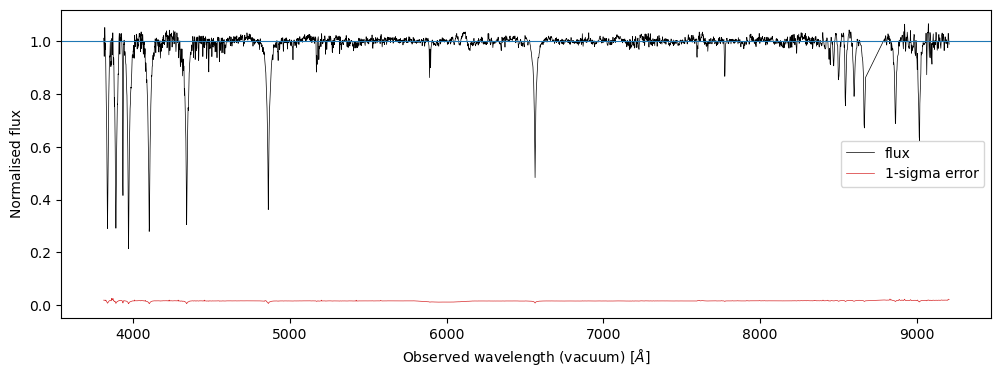

std of normalised flux in used pixels: 0.0127
median normalised error:               0.0162


In [8]:
normalised = normalise(spec, continuum)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(normalised.wave, normalised.flux, lw=0.5, color="k", label="flux")
ax.plot(normalised.wave, normalised.error, lw=0.5, color="C3",
        label="1-sigma error")
ax.axhline(1, color="C0", lw=0.8)
ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
ax.set_ylabel("Normalised flux")
ax.legend()
plt.show()

good = np.isfinite(normalised.flux) & used
print(f"std of normalised flux in used pixels: {np.std(normalised.flux[good]):.4f}")
print(f"median normalised error:               {np.median(normalised.error[good]):.4f}")

## Limitations

- The knot spacing is chosen by comparing fits by eye; the spread of
  the Balmer EWs over several spacings (section 4) is the resulting
  systematic error.
- In the used pixels the scatter of the normalised flux is ~25%
  smaller than the median SDSS error. Clipping at 2 sigma explains only
  ~6% (the std of a normal truncated at -2 sigma is 0.94); the rest is
  not explained yet (correlated pixels after resampling are the likely
  cause).
- The normalised error does not include the uncertainty of the
  continuum.
- Where the wings of neighbouring broad lines overlap, even the flux
  between them may sit below the true continuum, and the fit follows
  it (sections 1 and 3). A fit of each line together with a local
  continuum would be more accurate.